# Índice de contenidos
1. Antes de empezar:

2. Reto 1 - Importar y describir el conjunto de datos

    2.0.0.1 Explore el conjunto de datos con técnicas matemáticas y de visualización. ¿Qué encuentra?

3. Reto 2 - Limpieza y transformación de datos

4. Reto 3 - Preprocesamiento de datos

    4.0.0.1 Utilizaremos el StandardScaler de sklearn.preprocessing y escalaremos nuestros datos. Lea más sobre StandardScaler aquí.

5. Reto 4 - Agrupación de datos con K-Means

6. Reto 5 - Agrupación de datos con DBSCAN

7. Reto 6 - Comparar K-Means con DBSCAN

8. Reto adicional 2 - Cambiar el número de clusters de K-Means

9. Bonus Challenge 3 - Cambiar DBSCAN eps y min_samples

# Antes de empezar:
- Lee el archivo README.md
- Comenta todo lo que puedas y utiliza los recursos del archivo README.md
- ¡Feliz aprendizaje!

In [208]:
# Import your libraries:

%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import warnings                                              
from sklearn.exceptions import DataConversionWarning          
warnings.filterwarnings(action='ignore', category=DataConversionWarning)

# Desafío 1 - Importar y describir el conjunto de datos

En este laboratorio, utilizaremos un conjunto de datos que contiene información sobre las preferencias de los clientes. Analizaremos cuánto gasta cada cliente en un año en cada subcategoría de la tienda de comestibles e intentaremos encontrar similitudes mediante la agrupación.

El origen del conjunto de datos es [aquí](https://archive.ics.uci.edu/ml/datasets/wholesale+customers).

In [209]:
df = pd.read_csv('../data/Wholesale customers data.csv')
df.head()



,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


#### Explora el conjunto de datos con técnicas matemáticas y de visualización. ¿Qué encuentras?

Lista de comprobación:

* ¿Qué significa cada columna?
* ¿Hay datos categóricos que convertir?
* ¿Hay que eliminar datos que faltan?
* Colinealidad de columnas: ¿hay correlaciones altas?
* Estadísticas descriptivas: ¿hay que eliminar algún valor atípico?
* Distribución de los datos por columnas: ¿está sesgada la distribución?
* Etc.

Información adicional: Hace más de un siglo, un economista italiano llamado Vilfredo Pareto descubrió que aproximadamente el 20% de los clientes representan el 80% de las ventas minoristas típicas. Esto se denomina [principio de Pareto](https://en.wikipedia.org/wiki/Pareto_principle). Compruebe si este conjunto de datos presenta esta característica.

In [210]:
#Channel: Canal de ventas (1 o 2). Esto puede indicar si el cliente realiza compras en línea (canal 1) o en una tienda física (canal 2).
#Region: Región (1, 2 o 3). Representa la zona geográfica donde se encuentra el cliente.
#Fresh: Gasto anual en productos frescos (en unidades monetarias).
#Milk: Gasto anual en productos lácteos.
#Grocery: Gasto anual en productos de abarrotes.
#Frozen: Gasto anual en productos congelados.
#Detergents_Paper: Gasto anual en detergentes y productos de papel.
#Delicassen: Gasto anual en productos delicatessen.

In [211]:
df.isnull().sum()


Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

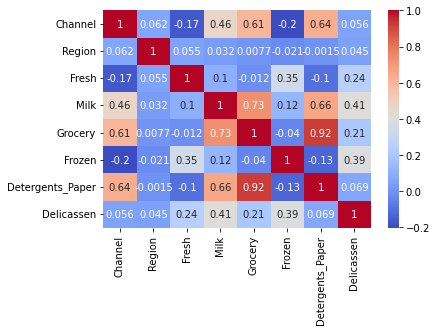

In [212]:
correlation_matrix = df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.show()


In [213]:
df.describe()


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


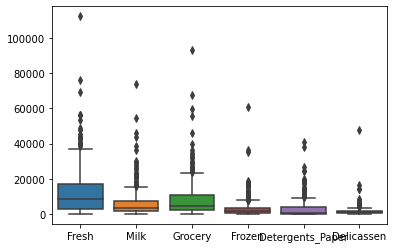

In [214]:
sns.boxplot(data=df[['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']])
plt.show()


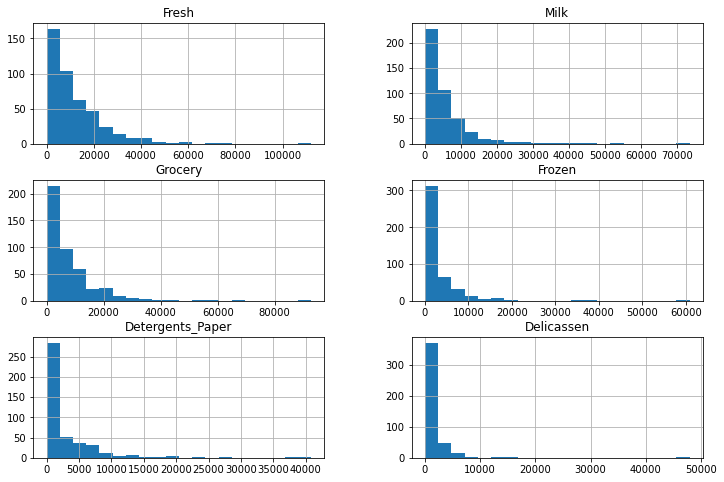

In [215]:
df[['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']].hist(bins=20, figsize=(12, 8))
plt.show()



**Tus observaciones aquí**


Channel y Region son variables categóricas

El conjunto de datos no tiene valores nulos

Frozen, Grocery, Milk y Detergents Paper tienen una gran correlación

El boxplot muestra que varias columnas, como Fresh, Milk y Frozen, contienen valores atípicos 

Los histogramas muestran una distribución sesgada a la derecha para casi todas las columnas

# Reto 2 - Limpieza y transformación de datos

Si tu conclusión del reto anterior es que los datos necesitan limpieza/transformación, hazlo en las celdas de abajo. Sin embargo, si su conclusión es que los datos no necesitan ser limpiados o transformados, no dudes en saltarte este reto. Si optas por esta última opción, explica los motivos.

In [216]:
from scipy import stats
z_scores = np.abs(stats.zscore(df.select_dtypes(include=[np.number])))

outliers = (z_scores > 3).all(axis=1)

df_cleaned = df[~outliers]

In [217]:
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1

df_cleaned = df[~((df < (Q1 - 1.5 * IQR)) | (df > (Q3 + 1.5 * IQR))).any(axis=1)]


In [218]:
print(f'Número de filas antes: {len(df)}')
print(f'Número de filas después: {len(df_cleaned)}')


Número de filas antes: 440
Número de filas después: 332


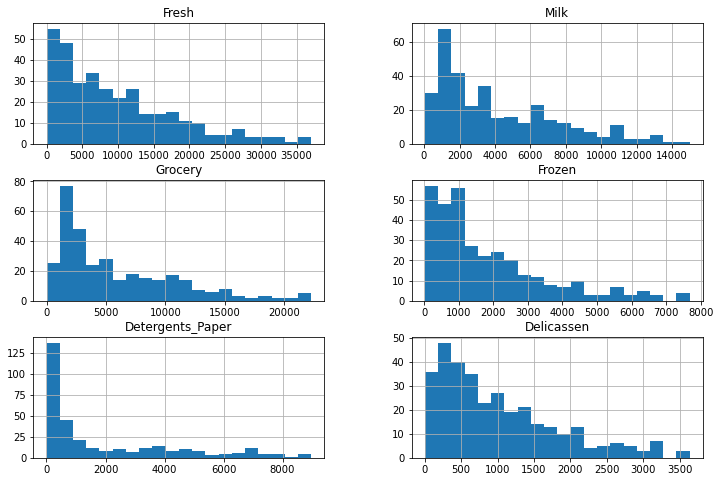

In [219]:
df_cleaned[['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']].hist(bins=20, figsize=(12, 8))
plt.show()

**Tus observaciones aquí**

+ Parece que después de eliminar los valores atípicos, las distribuciones de las variables han quedado más equilibradas,


# Reto 3 - Preprocesamiento de datos

Uno de los problemas del conjunto de datos es que los rangos de valores son notablemente diferentes en las distintas categorías (por ejemplo, `Fresh` y `Grocery` en comparación con `Detergents_Paper` y `Delicassen`). Si hiciste esta observación en el primer reto, ¡has hecho un gran trabajo! Esto significa que no sólo has completado las preguntas de bonificación en el anterior laboratorio de Aprendizaje Supervisado, sino que también has investigado en profundidad sobre [*feature scaling*](https://en.wikipedia.org/wiki/Feature_scaling). ¡Sigue trabajando así de bien!

Diversos rangos de valores en diferentes características podrían causar problemas en nuestra agrupación. La forma de reducir el problema es mediante el escalado de características. Volveremos a utilizar esta técnica con este conjunto de datos.

#### Utilizaremos el `StandardScaler` de `sklearn.preprocessing` y escalaremos nuestros datos. Lee más sobre `StandardScaler` [aquí](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler).

*Después de escalar tus datos, asigna los datos transformados a una nueva variable `customers_scale`.

In [220]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

columns_to_scale = df_cleaned.drop(columns=['Channel', 'Region']).columns

customers_scaled = scaler.fit_transform(df_cleaned[columns_to_scale])

customers_scaled_df = pd.DataFrame(customers_scaled, columns=columns_to_scale)

customers_scale = pd.concat([df_cleaned[['Channel', 'Region']], customers_scaled_df], axis=1)

customers_scale.head()



,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2.0,3.0,0.383041,1.652898,0.334978,-0.967004,0.305053,0.390465
1,2.0,3.0,-0.305588,1.698756,0.733878,-0.059255,0.569139,0.922591
3,1.0,3.0,-0.016491,1.236906,-0.148989,-0.701951,-0.069958,0.527749
5,2.0,3.0,-0.241535,0.253353,0.705655,-0.113790,0.581085,1.882360
6,2.0,3.0,-0.439829,-0.136137,0.062883,-0.843274,-0.103662,-0.323895


In [221]:
# Eliminar las filas con valores NaN
customers_scale = customers_scale.dropna()

# Reto 4 - Agrupación de datos con K-Means

Ahora vamos a agrupar los datos con K-Means primero. Inicia el modelo K-Means, luego ajusta tus datos escalados. En los datos devueltos por el método `.fit`, hay un atributo llamado `labels_` que es el número de cluster asignado a cada registro de datos. Lo que puede hacer es asignar estas etiquetas de nuevo a `customers` en una nueva columna llamada `customers['labels']`. Entonces verá los resultados de cluster de los datos originales.

In [222]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42) 

kmeans.fit(customers_scale)

customers_scale['labels'] = kmeans.labels_

customers_scale.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,labels
0,2.0,3.0,0.383041,1.652898,0.334978,-0.967004,0.305053,0.390465,1
1,2.0,3.0,-0.305588,1.698756,0.733878,-0.059255,0.569139,0.922591,1
3,1.0,3.0,-0.016491,1.236906,-0.148989,-0.701951,-0.069958,0.527749,1
5,2.0,3.0,-0.241535,0.253353,0.705655,-0.113790,0.581085,1.882360,1
6,2.0,3.0,-0.439829,-0.136137,0.062883,-0.843274,-0.103662,-0.323895,2


### Viendo el elbow pododríamos escoger 2 como el número de clusters correctos

In [223]:
kmeans_2 = KMeans(n_clusters=2).fit(customers_scale)

labels = kmeans_2.predict(customers_scale)

clusters = kmeans_2.labels_.tolist()

In [224]:
customers_scale['Label'] = clusters

Cuenta los valores en `labels`.

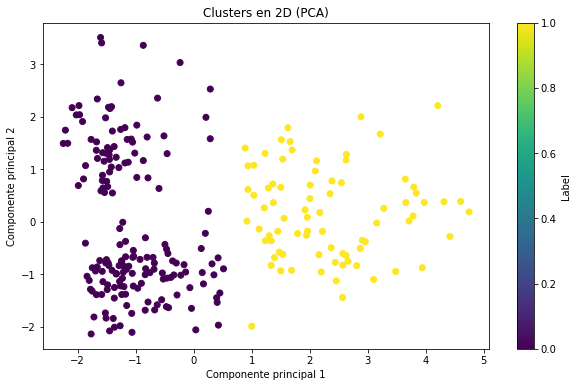

In [225]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
pca_components = pca.fit_transform(customers_scale)

# Graficamos los clusters
plt.figure(figsize=(10, 6))
plt.scatter(pca_components[:, 0], pca_components[:, 1], c=customers_scale['Label'], cmap='viridis')
plt.title('Clusters en 2D (PCA)')
plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.colorbar(label='Label')
plt.show()

In [226]:
label_counts = customers_scale['Label'].value_counts()
label_counts

0    172
1     79
Name: Label, dtype: int64

# Reto 5 - Clustering de datos con DBSCAN

Ahora vamos a agrupar los datos utilizando DBSCAN. Utiliza `DBSCAN(eps=0.5)` para iniciar el modelo y, a continuación, ajusta los datos escalados. En los datos devueltos por el método `.fit`, asigna las `labels_` de nuevo a `customers['labels_DBSCAN']`. Ahora tus datos originales tienen dos etiquetas, una de K-Means y la otra de DBSCAN.

In [227]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.5)

dbscan.fit(customers_scale)

customers_scale['labels_DBSCAN'] = dbscan.labels_

customers_scale[['labels', 'labels_DBSCAN']].head()



,labels,labels_DBSCAN
0,1,-1
1,1,-1
3,1,-1
5,1,-1
6,2,-1


Cuenta los valores en `labels_DBSCAN`.

In [228]:
customers_scale['labels_DBSCAN'].value_counts()


-1    241
 0      5
 1      5
Name: labels_DBSCAN, dtype: int64

# Reto 6 - Comparar K-Means con DBSCAN

Ahora queremos comparar visualmente cómo K-Means y DBSCAN han agrupado nuestros datos. Crearemos gráficos de dispersión para varias columnas. Para cada uno de los siguientes pares de columnas, traza un gráfico de dispersión utilizando `labels` y otro utilizando `labels_DBSCAN`. Ponlos uno al lado del otro para compararlos. ¿Qué algoritmo de agrupación tiene más sentido?

Columnas a visualizar:

* `Detergents_Paper` as X and `Milk` as y
* `Grocery` as X and `Fresh` as y
* `Frozen` as X and `Delicassen` as y

Visualice `Detergentes_Papel` como X y `Leche` como Y mediante `labels` y `labels_DBSCAN` respectivamente

In [229]:
def plot(x,y,hue):
    sns.scatterplot(x=x, 
                    y=y,
                    hue=hue)
    plt.title('Detergents Paper vs Milk ')
    return plt.show();

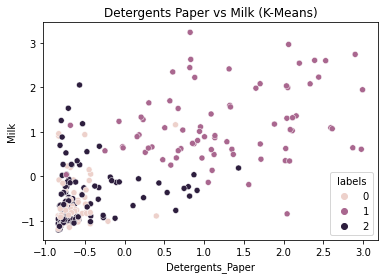

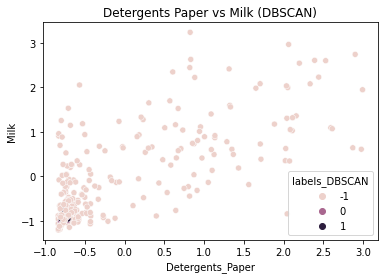

In [230]:
import seaborn as sns
import matplotlib.pyplot as plt

# Función para crear gráficos de dispersión
def plot(x, y, hue, title):
    sns.scatterplot(x=x, 
                    y=y,
                    hue=hue)
    plt.title(title)
    plt.show()

# Gráfico para K-Means
plot(x=customers_scale['Detergents_Paper'], y=customers_scale['Milk'], hue=customers_scale['labels'], title='Detergents Paper vs Milk (K-Means)')

# Gráfico para DBSCAN
plot(x=customers_scale['Detergents_Paper'], y=customers_scale['Milk'], hue=customers_scale['labels_DBSCAN'], title='Detergents Paper vs Milk (DBSCAN)')


Visualice `Grocery` como X y `Fresh` como Y mediante `labels` y `labels_DBSCAN` respectivamente

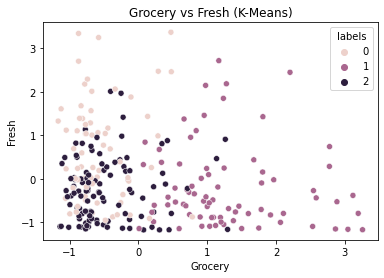

In [231]:
plot(x=customers_scale['Grocery'], y=customers_scale['Fresh'], hue=customers_scale['labels'], title='Grocery vs Fresh (K-Means)')

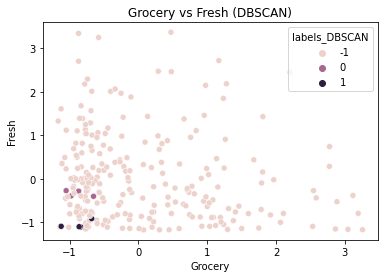

In [232]:
plot(x=customers_scale['Grocery'], y=customers_scale['Fresh'], hue=customers_scale['labels_DBSCAN'], title='Grocery vs Fresh (DBSCAN)')

Visualice `Frozen` como X y `Delicassen` como Y mediante `labels` y `labels_DBSCAN` respectivamente

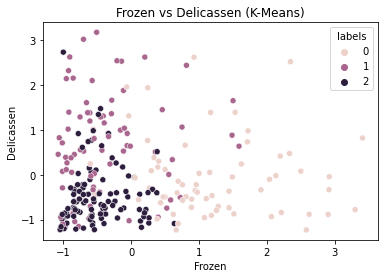

In [233]:
plot(x=customers_scale['Frozen'], y=customers_scale['Delicassen'], hue=customers_scale['labels'], title='Frozen vs Delicassen (K-Means)')

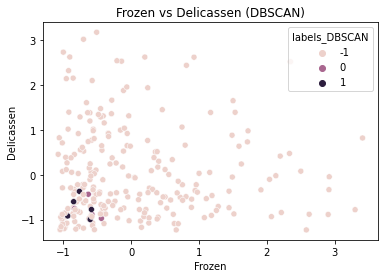

In [234]:
plot(x=customers_scale['Frozen'], y=customers_scale['Delicassen'], hue=customers_scale['labels_DBSCAN'], title='Frozen vs Delicassen (DBSCAN)')# Your code here:


Vamos a utilizar un groupby para ver cómo la media difiere entre los grupos. Agrupamos `customers` por `labels` y `labels_DBSCAN` respectivamente y calculamos las medias de todas las columnas.

In [235]:
kmeans_grouped = customers_scale.groupby('labels').mean()

dbscan_grouped = customers_scale.groupby('labels_DBSCAN').mean()

print("Media por grupo (K-Means):")
print(kmeans_grouped)

print("\nMedia por grupo (DBSCAN):")
print(dbscan_grouped)


Media por grupo (K-Means):
         Channel    Region     Fresh      Milk   Grocery    Frozen  \
labels                                                               
0       1.313433  2.328358  0.651182 -0.570725 -0.559209  1.167865   
1       1.272727  2.467532 -0.194741  1.169844  1.281887 -0.368113   
2       1.308411  2.401869 -0.262039 -0.465249 -0.480235 -0.501791   

        Detergents_Paper  Delicassen     Label  labels_DBSCAN  
labels                                                         
0              -0.626536   -0.048657  0.014925      -1.000000  
1               1.244306    0.649112  1.000000      -1.000000  
2              -0.506105   -0.477744  0.009346      -0.859813  

Media por grupo (DBSCAN):
                Channel    Region     Fresh      Milk   Grocery    Frozen  \
labels_DBSCAN                                                               
-1             1.311203  2.419087  0.030138  0.046486  0.077141  0.011821   
 0             1.000000  3.000000 -0.269782 

¿Qué algoritmo funciona mejor?

Elegiría DBSCAN
K-Means: Los clusters son bastante distintos entre sí, con medias que varían según las características. Los grupos 0, 1 y 2 tienen distribuciones claras, pero algo solapadas entre el 0 y el 2.
DBSCAN: Detecta un gran número de puntos como "ruido" (-1) y forma dos grupos pequeños. Los clusters 0 y 1 son más concentrados en características específicas.

# Bonus Challenge 2 - Cambiar el número de clusters de K-Means

Como hemos mencionado antes, no tenemos que preocuparnos por el número de clusters con DBSCAN porque lo decide automáticamente en función de los parámetros que le enviemos. Pero con K-Means, tenemos que suministrar el parámetro `n_clusters` (si no se suministra `n_clusters`, el algoritmo utilizará `8` por defecto). Debe saber que el número óptimo de clusters varía en función del conjunto de datos. K-Means puede funcionar mal si se utiliza un número incorrecto de clusters.

En el aprendizaje automático avanzado, los científicos de datos prueban diferentes números de clusters y evalúan los resultados con medidas estadísticas (leer [aquí](https://en.wikipedia.org/wiki/Cluster_analysis#External_evaluation)). Hoy no vamos a utilizar medidas estadísticas, sino nuestros ojos. En las celdas de abajo, experimenta con distintos números de conglomerados y visualízalos con gráficos de dispersión. ¿Qué número de clusters parece funcionar mejor para K-Means?

In [236]:
# Your code here


**Tus observaciones aquí**

* Viendo los gráficos del k-means ...

# Bonus Challenge 3 - Cambiar `eps` y `min_samples` de DBSCAN

Experimenta cambiando los parámetros `eps` y `min_samples` de DBSCAN. Mira cómo difieren los resultados con la visualización de gráficos de dispersión.

In [237]:
# Your code here


**Tus observaciones aquí**

    + El DBscan ajustado...
    
